# 02 · Rank distribution (log–log)

Checks how frequency decays with rank for first names: a log–log plot,
a histogram of frequencies, and the frequency-vs-rank relationship for the
top 1,000 names. Plots are embedded in the notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in test/; the datasets live in ../data/
DATA = Path("..") / "data"
NOMES_PATH = DATA / "nomes_censo2022_nomes.jsonl"
SOBRENOMES_PATH = DATA / "nomes_censo2022_sobrenomes.jsonl"
POP_BR_2022 = 203_080_756

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def load_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return pd.DataFrame([json.loads(line) for line in fh])

print("nomes:     ", NOMES_PATH.resolve())
print("sobrenomes:", SOBRENOMES_PATH.resolve())


nomes:      /home/user/nomescenso2022/data/nomes_censo2022_nomes.jsonl
sobrenomes: /home/user/nomescenso2022/data/nomes_censo2022_sobrenomes.jsonl


In [2]:
nomes = load_jsonl(NOMES_PATH)
nomes.describe()

,rank,frequencia,percent
count,128458.000000,1.284580e+05,128458.000000
mean,63572.498287,1.482066e+03,0.000719
std,36456.614006,4.452611e+04,0.021926
min,1.000000,2.000000e+01,0.000000
25%,31978.000000,3.000000e+01,0.000000
50%,64043.000000,5.300000e+01,0.000000
75%,94398.000000,1.440000e+02,0.000100
max,124180.000000,1.228448e+07,6.049100


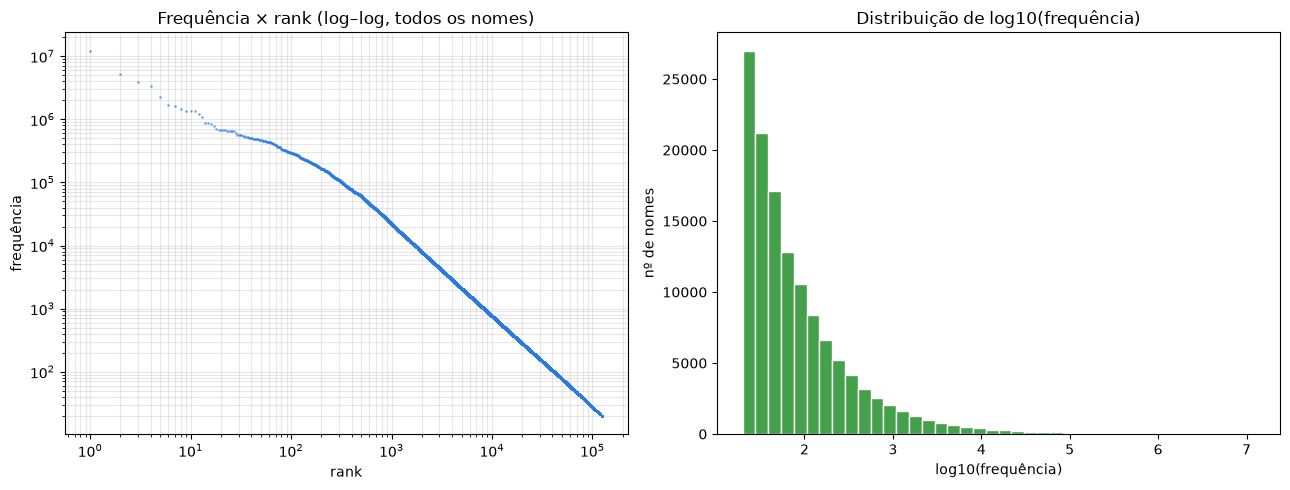

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].loglog(nomes["rank"], nomes["frequencia"], ".", ms=2, alpha=.5, color="#2a7ae2")
axes[0].set_title("Frequência × rank (log–log, todos os nomes)")
axes[0].set_xlabel("rank")
axes[0].set_ylabel("frequência")
axes[0].grid(alpha=.3, which="both")

axes[1].hist(np.log10(nomes["frequencia"]), bins=40, color="#44a04a", edgecolor="white")
axes[1].set_title("Distribuição de log10(frequência)")
axes[1].set_xlabel("log10(frequência)")
axes[1].set_ylabel("nº de nomes")
plt.tight_layout()
plt.show()

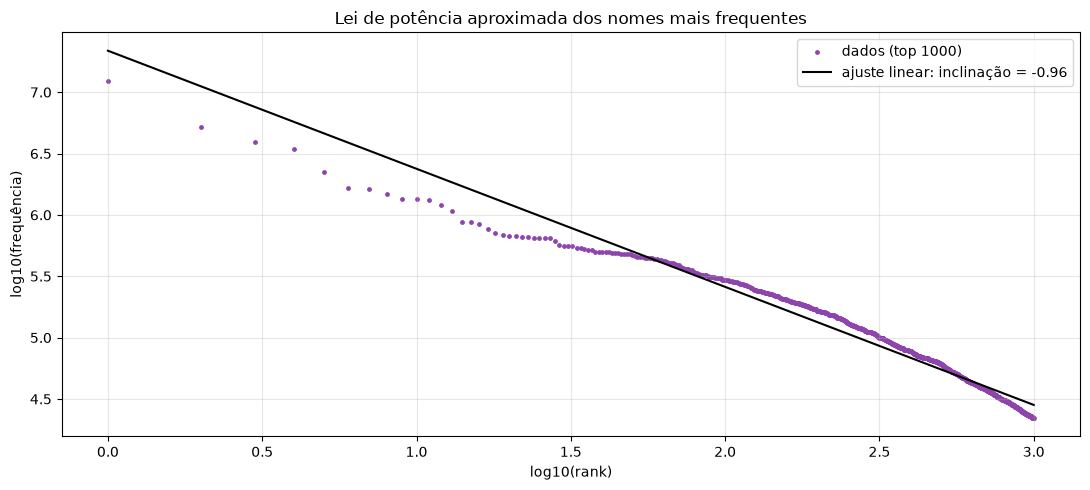

inclinação estimada: -0.962


In [4]:
top1k = nomes.head(1000).copy()
top1k["log_rank"] = np.log10(top1k["rank"])
top1k["log_freq"] = np.log10(top1k["frequencia"])
slope, intercept = np.polyfit(top1k["log_rank"], top1k["log_freq"], 1)

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(top1k["log_rank"], top1k["log_freq"], s=6, color="#8e44ad", label="dados (top 1000)")
xs = np.linspace(top1k["log_rank"].min(), top1k["log_rank"].max(), 100)
ax.plot(xs, slope * xs + intercept, color="black", lw=1.5,
        label=f"ajuste linear: inclinação = {slope:.2f}")
ax.set_xlabel("log10(rank)")
ax.set_ylabel("log10(frequência)")
ax.set_title("Lei de potência aproximada dos nomes mais frequentes")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()
print(f"inclinação estimada: {slope:.3f}")

In [5]:
# Ties: several names share a rank; check how many rank values repeat
ties = nomes.groupby("rank").size()
print("ranks com empate:", int((ties > 1).sum()))
print("maior grupo de empate:", int(ties.max()))
nomes[nomes["rank"].isin(ties[ties > 1].index[:5])]

ranks com empate: 2468
maior grupo de empate: 4279


,rank,nome,frequencia,percent
83,84,sonia,323710,0.1594
84,84,simone,323710,0.1594
439,440,geralda,68362,0.0337
440,440,denilson,68362,0.0337
579,580,leidiane,48068,0.0237
580,580,carmen,48068,0.0237
789,790,thamires,31393,0.0155
790,790,ronald,31393,0.0155
923,924,jhenifer,24689,0.0122
924,924,evellyn,24689,0.0122
